# Pump Predictive Maintenance

Condition-monitoring prototype for a single simulated pump. Vibration, temperature, pressure and motor current are recorded every minute. Random Forest flags unusual readings and Power BI brings the scores, sensor trends and alert details into one report.

The simulation reproduces the source notebook and retains the injected bearing wear, overheating and cavitation labels for evaluation.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

model_dir = Path.cwd() if Path("pump_pipeline.py").is_file() else Path("model").resolve()
sys.path.insert(0, str(model_dir))

from pump_pipeline import (
    PROJECT_ROOT,
    export_project,
    score_telemetry,
    simulate_telemetry,
    summarize,
)

## 1. Generate the minute readings

The simulation produces 5,000 readings for PUMP_UNIT_01, including 200 injected fault minutes. The injected labels represent the simulation's ground truth.

In [2]:
telemetry = simulate_telemetry()
print(f"{len(telemetry):,} minute readings")
display(telemetry["injected_fault"].value_counts().rename("Minutes").to_frame())
display(telemetry.head(3))

5,000 minute readings


,Minutes
injected_fault,
Nominal,4800
Overheating,68
Bearing wear,66
Cavitation,66


,timestamp,machine_id,vibration_mm_s,temperature_c,pressure_bar,motor_current_amp,injected_fault
0,2026-11-01 00:00:00,PUMP_UNIT_01,2.399,59.88,4.30,13.83,Nominal
1,2026-11-01 00:01:00,PUMP_UNIT_01,2.145,59.73,4.41,13.96,Nominal
2,2026-11-01 00:02:00,PUMP_UNIT_01,2.459,53.02,4.32,14.08,Nominal


## 2. Fit and score chronologically

- Fit Random Forest on the recorded injection labels in the first 3,000 minutes. Fit the scaler and two-component PCA on nominal training rows.
- Choose the score cutoff by F1 on the next 1,000 minutes, using their recorded injection labels.
- Score the final 1,000 minutes with the fitted model and frozen cutoff.

PCA reconstruction error is a secondary diagnostic. A higher Random Forest score gives stronger model evidence of a simulated fault. The fixed score cutoff drives the alert flag.

In [3]:
scored = score_telemetry(telemetry)
metrics = summarize(scored)
print(f"Fault score cutoff  {metrics['alert_cutoff']:.3f}")
print(f"Flagged minutes across all three segments  {metrics['flagged_minutes']:,}")
display(scored.groupby("data_split", sort=False).agg(
    Readings=("timestamp", "size"),
    Flagged_minutes=("anomaly_flag", "sum"),
))

Fault score cutoff  0.400
Flagged minutes across all three segments  197


,Readings,Flagged_minutes
data_split,,
Training,3000,130
Calibration,1000,35
Holdout,1000,32


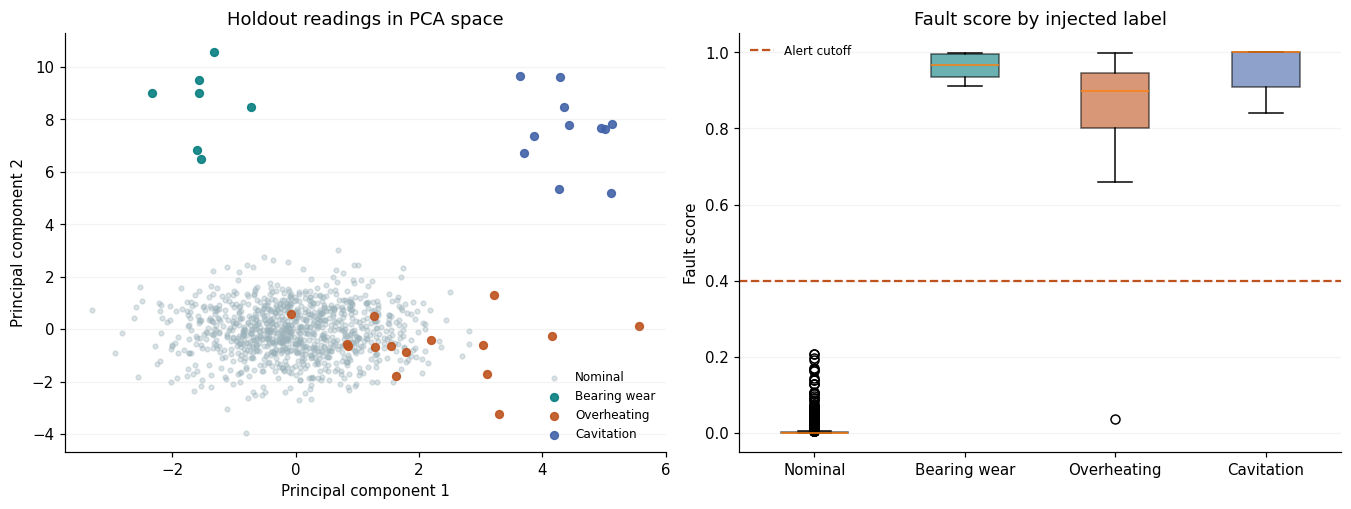

In [4]:
holdout = scored.loc[scored["data_split"].eq("Holdout")]
palette = {
    "Nominal": "#9AB1B9",
    "Bearing wear": "#087E80",
    "Overheating": "#BE531E",
    "Cavitation": "#4263A8",
}

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.6), layout="constrained")
for label, hue in palette.items():
    points = holdout.loc[holdout["injected_fault"].eq(label)]
    axes[0].scatter(
        points["pca_1"], points["pca_2"], s=10 if label == "Nominal" else 27,
        color=hue, alpha=0.35 if label == "Nominal" else 0.9, label=label,
    )
axes[0].set(title="Holdout readings in PCA space", xlabel="Principal component 1",
            ylabel="Principal component 2")
axes[0].legend(frameon=False, loc="best", fontsize=8)

scores = [holdout.loc[holdout["injected_fault"].eq(label), "fault_score"] for label in palette]
box = axes[1].boxplot(scores, tick_labels=list(palette), patch_artist=True)
for patch, hue in zip(box["boxes"], palette.values()):
    patch.set_facecolor(hue)
    patch.set_alpha(0.6)
axes[1].axhline(metrics["alert_cutoff"], color="#BE531E", linestyle="--", label="Alert cutoff")
axes[1].set(title="Fault score by injected label", ylabel="Fault score")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.15)
plt.show()

## 3. Measure detection on held-out minutes

Precision is the share of flagged holdout minutes that contain an injected fault. Recall is the share of injected holdout faults detected. The false alarm rate uses nominal holdout minutes as the denominator.

In [5]:
test = metrics["holdout"]
display(pd.DataFrame(
    [[test["true_negative"], test["false_positive"]], [test["false_negative"], test["true_positive"]]],
    columns=["Unflagged", "Flagged"], index=["Nominal", "Injected fault"],
))
for label, key in [
    ("Precision", "precision"), ("Recall", "recall"),
    ("F1 score", "f1"), ("False alarm rate", "false_alarm_rate"),
]:
    print(f"{label:17} {test[key]:.2%}")
display(pd.DataFrame.from_dict(test["by_injected_fault"], orient="index"))

Precision         100.00%
Recall            96.97%
F1 score          98.46%
False alarm rate  0.00%


,Unflagged,Flagged
Nominal,967,0
Injected fault,1,32


,injected,detected
Bearing wear,7,7
Overheating,15,14
Cavitation,11,11


## 4. Review example alerts

The sensor rules attach a suspected fault and a review cue to flagged readings. The outcome column records whether the flag matched an injected event in the holdout.

In [6]:
alert_fields = [
    "timestamp", "fault_score", "suspected_fault",
    "injected_fault", "outcome", "review_cue",
]
display(holdout.loc[holdout["anomaly_flag"].eq(1), alert_fields].nlargest(5, "fault_score"))

,timestamp,fault_score,suspected_fault,injected_fault,outcome,review_cue
4076,2026-11-03 19:56:00,1.0,Cavitation,Cavitation,True positive,Review pressure and vibration
4161,2026-11-03 21:21:00,1.0,Cavitation,Cavitation,True positive,Review pressure and vibration
4403,2026-11-04 01:23:00,1.0,Cavitation,Cavitation,True positive,Review pressure and vibration
4670,2026-11-04 05:50:00,1.0,Cavitation,Cavitation,True positive,Review pressure and vibration
4853,2026-11-04 08:53:00,1.0,Cavitation,Cavitation,True positive,Review pressure and vibration


## 5. Update the historical Power BI pages

Run the cell below with Power BI Desktop closed. It exports the scored CSV and embeds the same bytes in the historical Power Query source. Run **START_LIVE.cmd**, open **Pump_Maintenance_Live.pbip**, and use **Home → Refresh** once for the historical pages. The **Live Monitor** page queries the running feed every five seconds.

The holdout measures detection at the current reading in a simulation. Real failure lead time remains an open question.

In [7]:
export_project(scored, metrics)
print("Scored CSV  ", (PROJECT_ROOT / "data" / "pump_telemetry_scored.csv").name)
print("Power BI project  ", (PROJECT_ROOT / "Pump_Maintenance_Live.pbip").name)

Scored CSV   pump_telemetry_scored.csv
Power BI project   Pump_Maintenance_Live.pbip
